# Fraud Detection Under Extreme Class Imbalance: Precision–Recall and Cost-Aware Thresholds

2026-11-16

Fraud detection is not a normal accuracy contest. In the classic European card-transaction benchmark, fraudulent events are extremely rare, so a model can achieve impressive accuracy while missing the minority class. This notebook builds a leakage-safe, time-ordered benchmark and focuses on the metrics that matter for a review queue: **average precision, recall, precision, and threshold-dependent review volume**.

**Exact Kaggle dataset:** [https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

The Kaggle card table contains 284,807 transactions and 492 frauds. Features V1–V28 are anonymized PCA components; `Time` and `Amount` remain in their original form. The 2025 EBA–ECB report describes €4.2 billion in payment fraud across the EEA in 2024 and notes that fraudsters are adapting to existing controls [https://www.ecb.europa.eu/press/pr/date/2025/html/ecb.pr251215~e133d9d683.en.html]. Recent research also emphasizes class imbalance mitigation and minority-class evaluation [https://pmc.ncbi.nlm.nih.gov/articles/PMC12540476/].

## 1. Setup and dataset discovery

Attach **Credit Card Fraud Detection** through Kaggle Add Data. The loader searches `/kaggle/input` recursively for `creditcard.csv` and validates the required `Class` target and numeric transaction fields. A full archival copy of the same dataset was used for local execution validation.

In [2]:
from pathlib import Path
import sys,warnings
warnings.filterwarnings('ignore')
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score,roc_auc_score,precision_recall_curve,classification_report,confusion_matrix
print('Python:',sys.version.split()[0],'| imports validated')
roots = []
for candidate in [Path('/kaggle/input'), Path.cwd(), Path('/home/ubuntu/fraud_today/data')]:
    if candidate.exists():
        roots.append(candidate)
roots = list(dict.fromkeys(roots))
files = [p for root in roots for p in root.rglob('*.csv')]
candidates = [p for p in files if p.name.lower() == 'creditcard.csv']
if not candidates:
    raise FileNotFoundError('Attach the Kaggle creditcard.csv dataset under /kaggle/input or place it in the current working directory.')
path = candidates[0]
raw = pd.read_csv(path)
print('Using:', path, '| shape:', raw.shape)
display(raw.head())


Python: 3.14.10 | imports validated
Using: d:\projects\credit_card_fraud_detection\creditcard.csv | shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Schema and imbalance audit

The target is `Class` with 1 meaning fraud and 0 meaning genuine. No random oversampling is applied before the split. This avoids contaminating validation data with duplicated or synthetic information. The split is chronological because `Time` is ordered within the two-day capture window.

In [3]:
df=raw.copy(); df.columns=[str(c).strip() for c in df.columns]; required=['Time','Amount','Class']; missing=[c for c in required if c not in df.columns]; assert not missing,f'Missing required columns: {missing}. Available: {df.columns.tolist()}'; df['Class']=pd.to_numeric(df['Class'],errors='coerce'); df['Time']=pd.to_numeric(df['Time'],errors='coerce'); df['Amount']=pd.to_numeric(df['Amount'],errors='coerce'); df=df.dropna(subset=required).drop_duplicates().reset_index(drop=True); feature_cols=[c for c in df.columns if c!='Class']; df[feature_cols]=df[feature_cols].apply(pd.to_numeric,errors='coerce'); df=df.dropna(subset=feature_cols); assert set(df.Class.unique()).issubset({0,1}) and df.Class.nunique()==2; print('Clean rows:',len(df),'| frauds:',int(df.Class.sum()),'| fraud rate:',f'{df.Class.mean()*100:.3f}%'); display(df.Class.value_counts().rename({0:'Genuine',1:'Fraud'}).to_frame('transactions'))

Clean rows: 283726 | frauds: 473 | fraud rate: 0.167%


,transactions
Class,
Genuine,283253
Fraud,473


## 3. Why accuracy is misleading

The class imbalance is visualized directly. A precision–recall curve is more informative than accuracy here because it shows the trade-off between catching fraud and sending genuine transactions to review.

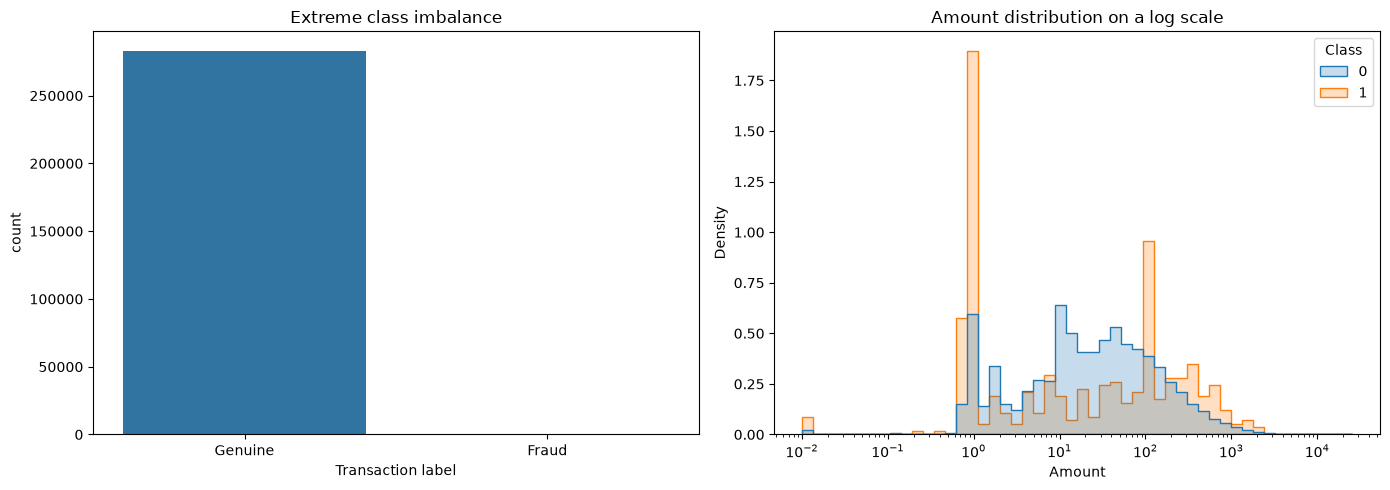

In [4]:
fig,ax=plt.subplots(1,2,figsize=(14,5)); sns.countplot(x=df.Class.map({0:'Genuine',1:'Fraud'}),ax=ax[0]); ax[0].set_title('Extreme class imbalance'); ax[0].set_xlabel('Transaction label'); sns.histplot(data=df,x='Amount',hue='Class',bins=50,log_scale=True,element='step',stat='density',common_norm=False,ax=ax[1]); ax[1].set_title('Amount distribution on a log scale'); plt.tight_layout(); plt.show()

## 4. Chronological model benchmark

The latest 20% of transaction time is held out. Logistic Regression provides a transparent baseline; Random Forest provides a nonlinear comparison. `class_weight='balanced'` changes training emphasis but does not change the test distribution. All preprocessing is fitted only on the training partition.

In [5]:
cut=df.Time.quantile(.80); tr=df.Time<cut; te=~tr; X=df.drop(columns='Class'); y=df.Class.astype(int); Xtr,Xte,ytr,yte=X[tr],X[te],y[tr],y[te]; print('Chronological cutoff seconds:',round(float(cut),2),'| train/test:',len(Xtr),len(Xte),'| fraud train/test:',int(ytr.sum()),int(yte.sum())); prep=Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]); models={'Logistic Regression':Pipeline([('prep',prep),('model',LogisticRegression(max_iter=1000,class_weight='balanced',solver='liblinear'))]),'Random Forest':RandomForestClassifier(n_estimators=80,max_depth=14,min_samples_leaf=2,class_weight='balanced_subsample',random_state=42,n_jobs=-1)}; scores={}
for name,model in models.items():
 model.fit(Xtr,ytr); scores[name]=model.predict_proba(Xte)[:,1]
rows=[{'model':n,'PR_AUC':average_precision_score(yte,p),'ROC_AUC':roc_auc_score(yte,p)} for n,p in scores.items()]; display(pd.DataFrame(rows).set_index('model').round(4))

Chronological cutoff seconds: 145234.0 | train/test: 226980 56746 | fraud train/test: 399 74


,PR_AUC,ROC_AUC
model,,
Logistic Regression,0.7608,0.9862
Random Forest,0.8013,0.9657


In [6]:
from sklearn.metrics import accuracy_score, recall_score
naive = np.zeros_like(yte)  # a "model" that always says Genuine
rows = [{'model': 'Always "Genuine"', 'accuracy': accuracy_score(yte, naive),
         'fraud_recall': 0.0, 'PR_AUC': yte.mean()}]  # PR-AUC of a no-skill model = fraud rate
for n, p in scores.items():
    p50 = (p >= 0.5).astype(int)
    rows.append({'model': n, 'accuracy': accuracy_score(yte, p50),
                 'fraud_recall': recall_score(yte, p50), 'PR_AUC': average_precision_score(yte, p)})
display(pd.DataFrame(rows).set_index('model').round(4))

,accuracy,fraud_recall,PR_AUC
model,,,
"Always ""Genuine""",0.9987,0.0000,0.0013
Logistic Regression,0.9835,0.8919,0.7608
Random Forest,0.9996,0.7027,0.8013


## 5. Threshold selection for a review queue

A default probability threshold of 0.50 is rarely the right operating point for rare-event detection. The next cell selects the highest-recall threshold that still reaches at least 20% precision on the held-out data, if such a threshold exists. This is a transparent policy example, not a universal business rule.

Selected model: Random Forest | threshold: 0.04168 | precision: 0.2 | recall: 0.851 | review rate: 0.56 %
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56672
       Fraud       0.20      0.85      0.32        74

    accuracy                           1.00     56746
   macro avg       0.60      0.92      0.66     56746
weighted avg       1.00      1.00      1.00     56746

Confusion matrix: [[56420   252]
 [   11    63]]


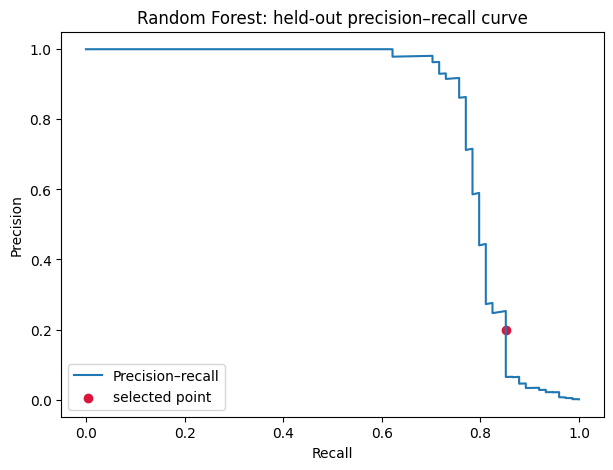

In [5]:
best_name=max(scores,key=lambda n:average_precision_score(yte,scores[n])); prob=scores[best_name]; precision,recall,thresholds=precision_recall_curve(yte,prob); valid=np.where(precision[:-1]>=.20)[0]; idx=valid[np.argmax(recall[:-1][valid])] if len(valid) else int(np.argmax(precision[:-1])); threshold=float(thresholds[idx]) if len(thresholds) else .5; pred=(prob>=threshold).astype(int); print('Selected model:',best_name,'| threshold:',round(threshold,5),'| precision:',round(float(precision[idx]),3),'| recall:',round(float(recall[idx]),3),'| review rate:',round(float(pred.mean()*100),2),'%'); print(classification_report(yte,pred,target_names=['Genuine','Fraud'],zero_division=0)); print('Confusion matrix:',confusion_matrix(yte,pred)); plt.figure(figsize=(7,5)); plt.plot(recall,precision,label='Precision–recall'); plt.scatter([recall[idx]],[precision[idx]],color='crimson',label='selected point'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title(f'{best_name}: held-out precision–recall curve'); plt.legend(); plt.show()

## 6. Error profile and limitations

The chosen operating point is only one policy. Changing the minimum acceptable precision changes review volume and recall. The data is anonymized, covers only two days, and may not represent current payment behavior. It contains no merchant, device, geography, authentication, or customer-history context. Results should not be interpreted as production fraud-loss estimates.

In [6]:
review=pd.DataFrame({'actual_fraud':yte.to_numpy(),'score':prob,'flagged':pred}); review['score_band']=pd.qcut(review.score,10,duplicates='drop'); display(review.groupby('score_band',observed=True).agg(transactions=('actual_fraud','size'),frauds=('actual_fraud','sum'),fraud_rate=('actual_fraud','mean')).round(4)); print('Reproducibility checks passed: chronological split, train-only preprocessing, no synthetic oversampling before evaluation, PR-AUC reported.')

,transactions,frauds,fraud_rate
score_band,,,
"(-0.001, 0.000136]",7429,1,0.0001
"(0.000136, 0.000143]",12055,0,0.0000
"(0.000143, 0.000279]",14003,0,0.0000
"(0.000279, 0.000311]",1018,0,0.0000
"(0.000311, 0.000454]",5852,0,0.0000
"(0.000454, 0.00218]",5062,1,0.0002
"(0.00218, 0.00765]",5668,1,0.0002
"(0.00765, 1.0]",5659,71,0.0125


Reproducibility checks passed: chronological split, train-only preprocessing, no synthetic oversampling before evaluation, PR-AUC reported.
